<img src="https://www.fct.unl.pt/sites/default/files/imagens/departamentos/logos/pt_df_rgb_positivo_h.png" width="250" />

## *Métodos de Imagem Médica - MIM*

**Projeto realizado por:**  Guilherme Leiria (N.º 70783) e Rafael Gonçalves (N.º 71250)

**Docente:** Professora Ana Rita Londral

**Data:** 25/11/2026


________________________________________________________________________________________________________________________________________________________________

# 🧠 **DIPY Demonstrador | Reconstrução Tridimensional das Conexões Cerebrais**

A **ressonância magnética de difusão** (*dMRI*) é uma técnica de imagem médica que permite estudar o movimento das moléculas de água nos tecidos biológicos. No cérebro, esta informação pode ser utilizada para investigar a organização da **substância branca**, através de métodos computacionais como a *tractografia*, que permite estimar trajetórias associadas aos feixes de fibras nervosas (axónios).

O presente **Jupyter Notebook** tem como objetivo demonstrar algumas das principais funcionalidades da biblioteca [**DIPY — Diffusion Imaging in Python**](https://dipy.org/), utilizando o dataset *Stanford HARDI*. Ao longo do trabalho, serão aplicados os modelos **DTI** (*Diffusion Tensor Imaging*) e **CSA** (*Constant Solid Angle*) para analisar a difusão, calcular mapas de anisotropia e reconstruir trajetórias tridimensionais da substância branca.

Por fim, será avaliada a influência de três limiares de **anisotropia fracionária generalizada (GFA)** — `0.15`, `0.25` e `0.35` — no número e comprimento das trajetórias reconstruídas, recorrendo a gráficos comparativos e visualizações **3D estáticas e interativas**.

> **Objetivo final:** Demonstrar as potencialidades do DIPY no processamento de imagens médicas e compreender a influência dos parâmetros computacionais na reconstrução e interpretação das trajetórias cerebrais.

## **Bibliotecas e Configuração Inicial**

- Importação das bibliotecas necessárias, definição dos parâmetros da experiência e apresentação das versões do Python e das bibliotecas utilizadas.

In [1]:
# libraries
from importlib.metadata import version
from IPython.display import display
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib

from dipy.data import default_sphere, get_fnames
from dipy.core.gradients import gradient_table
from dipy.io.gradients import read_bvals_bvecs
from dipy.io.image import load_nifti
from dipy.reconst.dti import TensorModel
from dipy.reconst.shm import CsaOdfModel
from dipy.direction import peaks_from_model
from dipy.tracking import utils
from dipy.tracking.stopping_criterion import ThresholdStoppingCriterion
from dipy.tracking.tracker import eudx_tracking
from dipy.tracking.streamline import Streamlines, length

plt.rcParams["figure.dpi"] = 110

LIMIARES_GFA = [0.15, 0.25, 0.35]
LIMIAR_REFERENCIA = 0.25
CORES_LIMIARES = {0.15: "#237aa6", 0.25: "#d68b27", 0.35: "#8e5db7"}

SEMENTE_ALEATORIA = 2026
DENSIDADE_SEMENTES = [1, 1, 1]
PASSO_MM = 0.5
ANGULO_MAX_GRAUS = 60
COMPRIMENTO_MIN_MM = 10.0
COMPRIMENTO_MAX_MM = 200.0

print("python:", sys.version.split()[0])
print("===============")
for pacote in ("dipy", "numpy", "pandas", "matplotlib", "nibabel", "scipy", "plotly"):
    print(f"{pacote}: {version(pacote)}")

python: 3.13.2
dipy: 1.12.1
numpy: 2.5.4
pandas: 3.1.1
matplotlib: 3.10.1
nibabel: 5.4.2
scipy: 1.18.1
plotly: 7.1.0


## **Carregamento do Dataset Stanford HARDI**

- Carregamento das imagens de MRI de difusão, preparação dos parâmetros de aquisição, definição das máscaras cerebrais e apresentação das principais características do dataset.

In [2]:
# dataset Stanford HARDI
dwi_path, bvals_path, bvecs_path = get_fnames(name="stanford_hardi")
labels_path = get_fnames(name="stanford_labels")

dwi, affine = load_nifti(dwi_path)
labels, affine_labels = load_nifti(labels_path)

bvals, bvecs = read_bvals_bvecs(bvals_path, bvecs_path)
gtab = gradient_table(bvals, bvecs=bvecs)


if dwi.shape[:3] != labels.shape or not np.allclose(affine, affine_labels, atol=1e-3):
    raise ValueError("As imagens DWI e os rótulos não estão alinhados.")


white_matter = (labels == 1) | (labels == 2)
seed_mask = labels == 2

b0 = np.mean(dwi[..., gtab.b0s_mask], axis=-1)


print("Dimensões DWI:", dwi.shape)
print("Dimensões do voxel:", np.round(nib.affines.voxel_sizes(affine), 2), "mm")
print("Volumes b0:", gtab.b0s_mask.sum())
print("Volumes com difusão:", (~gtab.b0s_mask).sum())
print("Valores de b (s/mm²):", np.unique(np.round(bvals / 100) * 100))
print("Voxels da substância branca:", white_matter.sum())
print("Voxels da região de sementes:", seed_mask.sum())

[2026-11-22 11:45:26][dipy] INFO: Dataset is already in place. If you want to fetch it again please first remove the folder C:\Users\rafae\.dipy\stanford_hardi 
[2026-11-22 11:45:26][dipy] INFO: Dataset is already in place. If you want to fetch it again please first remove the folder C:\Users\rafae\.dipy\stanford_hardi 
Dimensões DWI: (81, 106, 76, 160)
Dimensões do voxel: [2. 2. 2.] mm
Volumes b0: 10
Volumes com difusão: 150
Valores de b (s/mm²): [   0. 2000.]
Voxels da substância branca: 58788
Voxels da região de sementes: 505


## **Visualização das Imagens de MRI**

- Visualização dos cortes axial e sagital da MRI de referência e identificação da substância branca através da sobreposição da respetiva máscara.

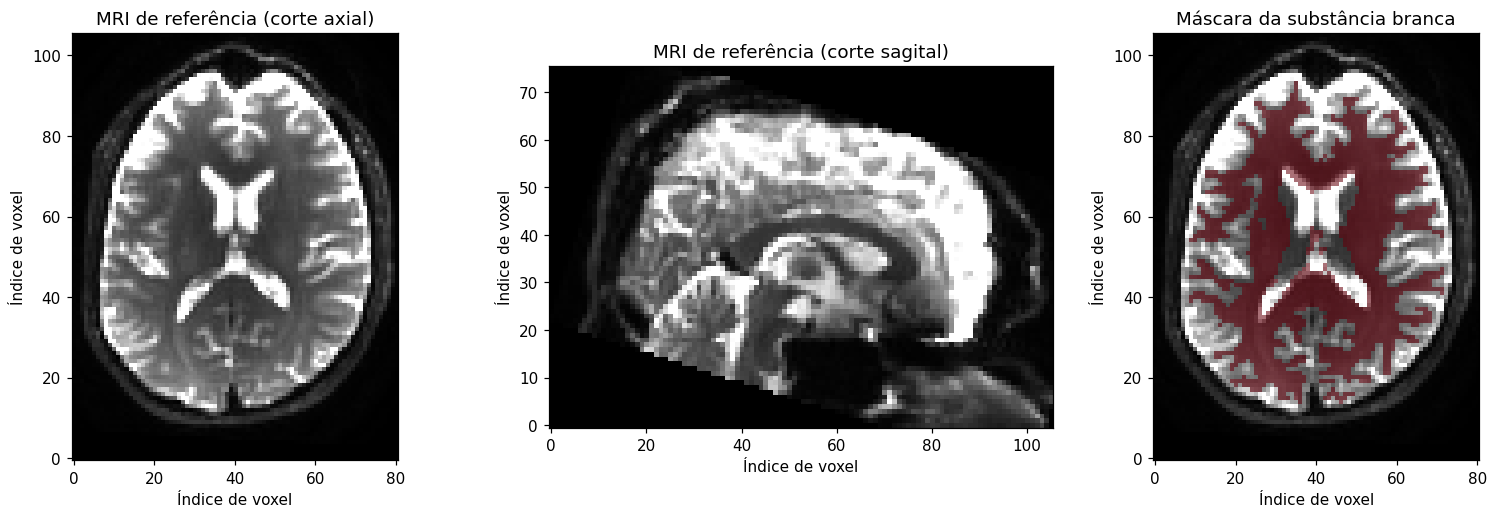

In [3]:
xi = b0.shape[0] // 2
zi = b0.shape[2] // 2

imagem_axial = b0[:, :, zi].T
mascara_axial = white_matter[:, :, zi].T
intensidade_max = np.percentile(b0[white_matter], 99.5)

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6), constrained_layout=True)

axes[0].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[0].set_title("MRI de referência (corte axial)")

axes[1].imshow(b0[xi, :, :].T, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[1].set_title("MRI de referência (corte sagital)")

axes[2].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[2].imshow(np.ma.masked_equal(mascara_axial, 0), cmap="Reds", alpha=0.56, origin="lower", vmin=0, vmax=1)
axes[2].set_title("Máscara da substância branca")

for ax in axes:
    ax.set_xlabel("Índice de voxel")
    ax.set_ylabel("Índice de voxel")
    ax.set_aspect("equal")

plt.show()

## **Análise da Difusão através do Modelo DTI**

- Aplicação do modelo de tensor de difusão (DTI) para calcular e visualizar os mapas de anisotropia fracionária (FA) e difusividade média (MD), incluindo os respetivos valores medianos na substância branca.

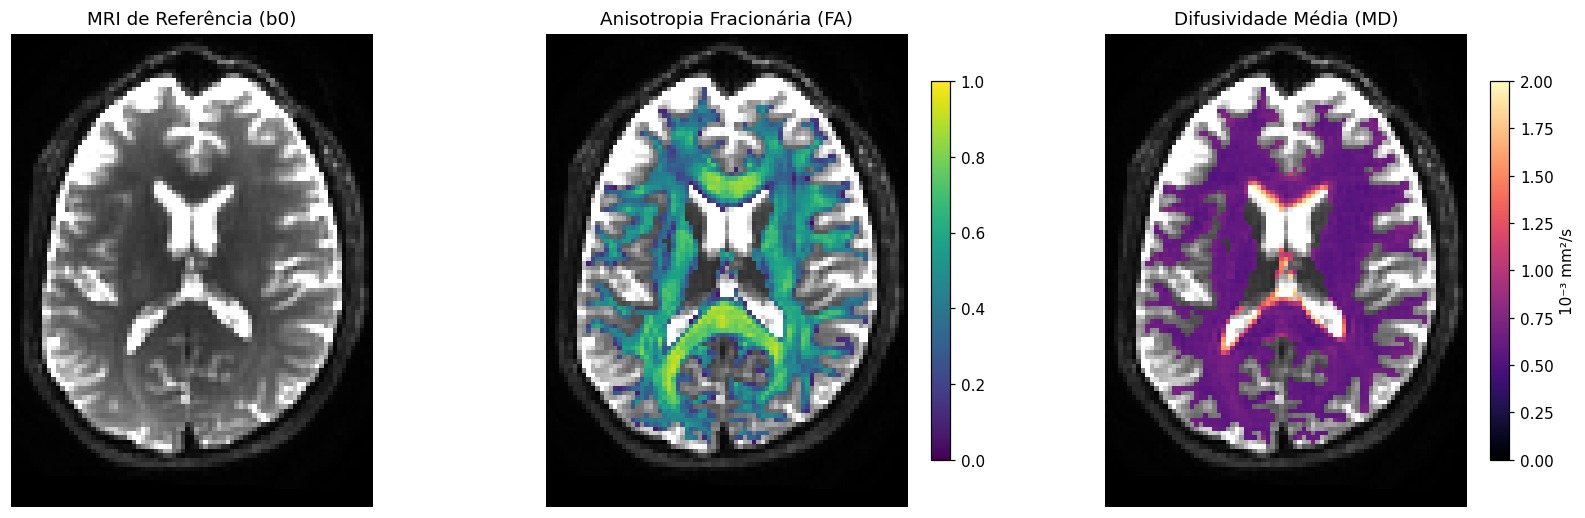

FA mediana: 0.426
MD mediana: 0.614 × 10⁻³ mm²/s


In [4]:
model_dti = TensorModel(gtab)
fit_dti = model_dti.fit(dwi, mask=white_matter)

fa = np.clip(np.nan_to_num(fit_dti.fa, nan=0, posinf=0, neginf=0), 0, 1)
md = np.maximum(np.nan_to_num(fit_dti.md, nan=0, posinf=0, neginf=0), 0)

fa_axial = np.ma.masked_where(~mascara_axial, fa[:, :, zi].T)
md_axial = np.ma.masked_where(~mascara_axial, md[:, :, zi].T * 1000)

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.6), constrained_layout=True)

for ax in axes:
    ax.imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
    ax.axis("off")

axes[0].set_title("MRI de Referência (b0)")

im_fa = axes[1].imshow(fa_axial, cmap="viridis", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Anisotropia Fracionária (FA)")
fig.colorbar(im_fa, ax=axes[1], shrink=0.8)

im_md = axes[2].imshow(md_axial, cmap="magma", origin="lower", vmin=0, vmax=2)
axes[2].set_title("Difusividade Média (MD)")
fig.colorbar(im_md, ax=axes[2], shrink=0.8, label="10⁻³ mm²/s")

plt.show()

print(f"FA mediana: {np.median(fa[white_matter]):.3f}")
print(f"MD mediana: {1000 * np.median(md[white_matter]):.3f} × 10⁻³ mm²/s")

## **Análise da Difusão através do Modelo CSA**

- Aplicação do modelo CSA para estimar as orientações de difusão, calcular e visualizar o mapa de anisotropia generalizada (GFA) e comparar diferentes limiares de GFA na substância branca.

GFA — percentis P10/P50/P90: [0.225 0.398 0.586]


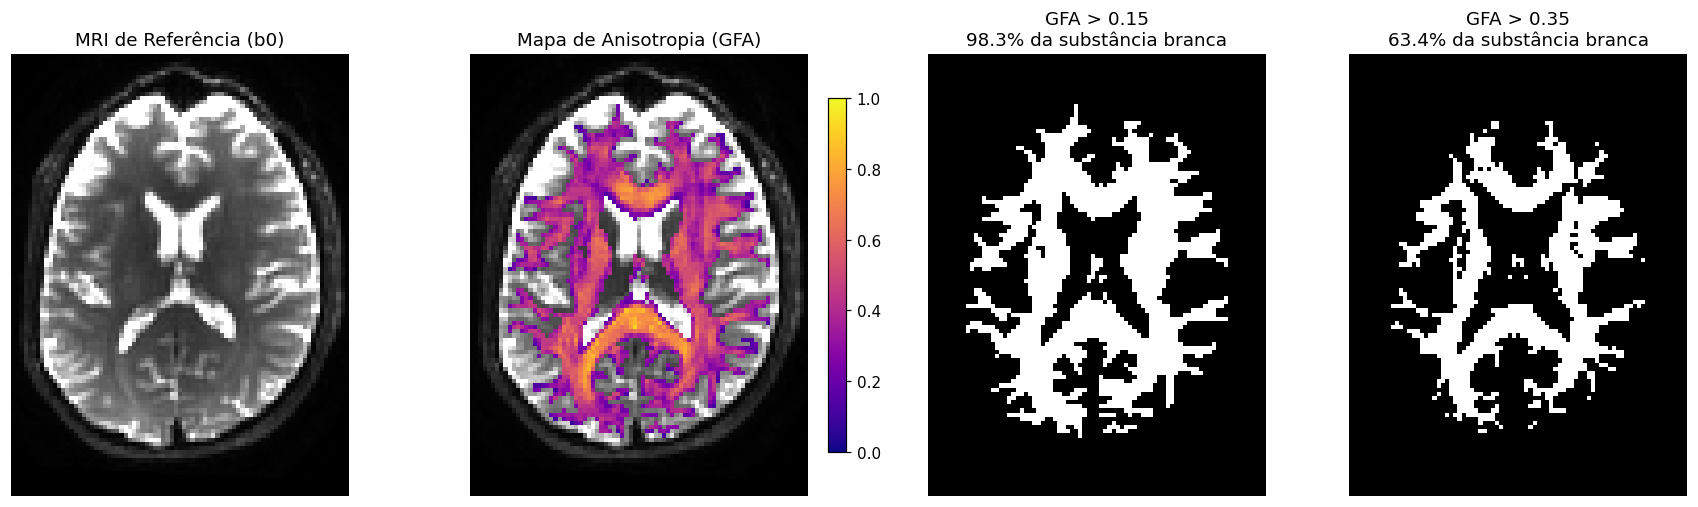

In [5]:
csa_model = CsaOdfModel(gtab, sh_order_max=6)

csa_peaks = peaks_from_model(csa_model, dwi, default_sphere, relative_peak_threshold=0.8, min_separation_angle=45, mask=white_matter)

gfa = np.clip(np.nan_to_num(csa_peaks.gfa, nan=0, posinf=0, neginf=0), 0, 1)

print("GFA — percentis P10/P50/P90:", np.round(np.percentile(gfa[white_matter], [10, 50, 90]), 3))

fig, axes = plt.subplots(1, 4, figsize=(16, 4.5), constrained_layout=True)

axes[0].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)
axes[0].set_title("MRI de Referência (b0)")
axes[1].imshow(imagem_axial, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)

gfa_axial = np.ma.masked_where(~mascara_axial, gfa[:, :, zi].T)
im = axes[1].imshow(gfa_axial, cmap="plasma", origin="lower", vmin=0, vmax=1)
axes[1].set_title("Mapa de Anisotropia (GFA)")
fig.colorbar(im, ax=axes[1], shrink=0.8)

for i, limiar in enumerate([0.15, 0.35], start=2):
    mascara_gfa = mascara_axial & (gfa[:, :, zi].T > limiar)
    percentagem = 100 * np.mean(gfa[white_matter] > limiar)
    axes[i].imshow(mascara_gfa, cmap="gray", origin="lower", vmin=0, vmax=1)
    axes[i].set_title(f"GFA > {limiar:.2f}\n{percentagem:.1f}% da substância branca")

for ax in axes:
    ax.axis("off")

plt.show()

## **Definição das Sementes para a Tractografia**

- Geração das sementes no corpo caloso, visualização da região selecionada e análise da distribuição da GFA na substância branca, com identificação dos diferentes limiares utilizados.

Número de sementes: 505
Limiares GFA: [0.15, 0.25, 0.35]
Passo: 0.5 mm | Ângulo máximo: 60°


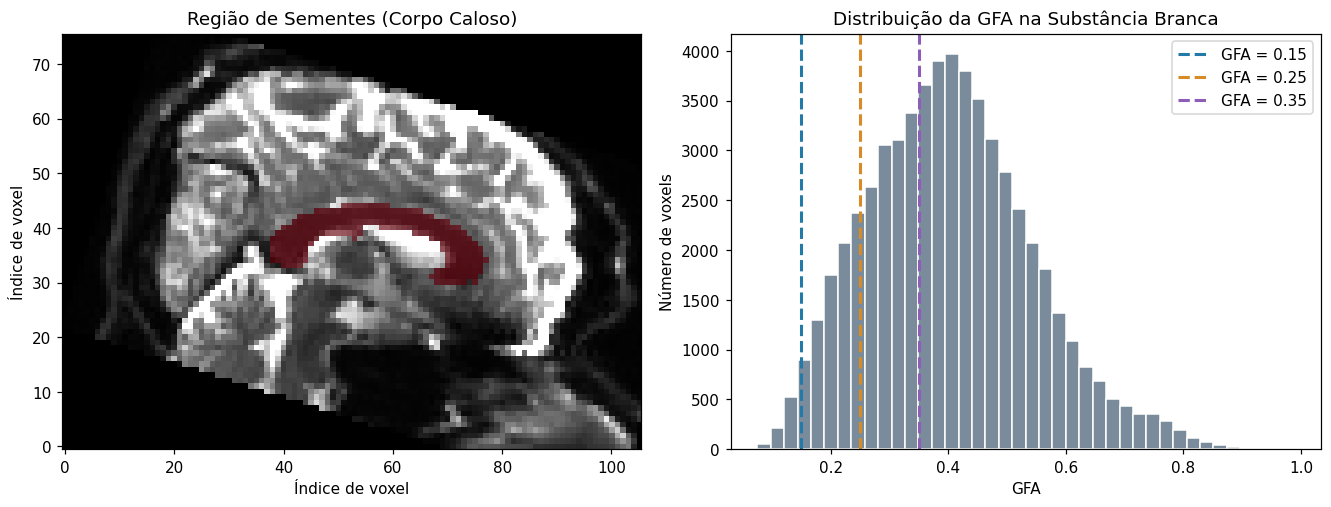

In [6]:
seeds = utils.seeds_from_mask(seed_mask, affine, density=DENSIDADE_SEMENTES)

print(f"Número de sementes: {len(seeds)}")
print(f"Limiares GFA: {LIMIARES_GFA}")
print(f"Passo: {PASSO_MM} mm | Ângulo máximo: {ANGULO_MAX_GRAUS}°")

x_roi = int(np.median(np.where(seed_mask)[0]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)

axes[0].imshow(b0[x_roi, :, :].T, cmap="gray", origin="lower", vmin=0, vmax=intensidade_max)

axes[0].imshow(np.ma.masked_equal(seed_mask[x_roi, :, :].T, 0), cmap="Reds", origin="lower", vmin=0, vmax=1, alpha=0.65)

axes[0].set_title("Região de Sementes (Corpo Caloso)")
axes[0].set_xlabel("Índice de voxel")
axes[0].set_ylabel("Índice de voxel")

axes[1].hist(gfa[white_matter], bins=40, color="#7a8c9c", edgecolor="white")

for limiar in LIMIARES_GFA:
    axes[1].axvline(limiar, color=CORES_LIMIARES[limiar], linestyle="--", linewidth=2, label=f"GFA = {limiar:.2f}")

axes[1].set_title("Distribuição da GFA na Substância Branca")
axes[1].set_xlabel("GFA")
axes[1].set_ylabel("Número de voxels")
axes[1].legend()

plt.show()

## **Reconstrução das Trajetórias por Tractografia**

- Aplicação do algoritmo de tractografia EuDX para reconstruir trajetórias da substância branca com diferentes limiares de GFA, filtrar as trajetórias pelo comprimento e comparar os resultados obtidos.

In [7]:
resultados = []
tracks_por_limiar = {}
comprimentos_por_limiar = {}

for limiar in LIMIARES_GFA:

    criterio = ThresholdStoppingCriterion(gfa, limiar)

    brutas = Streamlines(eudx_tracking(seeds, criterio, affine, pam=csa_peaks, step_size=PASSO_MM, max_cross=1, max_angle=ANGULO_MAX_GRAUS, random_seed=SEMENTE_ALEATORIA, nbr_threads=1))

    comprimentos = np.array([length(track) for track in brutas])
    validas = (comprimentos >= COMPRIMENTO_MIN_MM) & (comprimentos <= COMPRIMENTO_MAX_MM)

    retidas = Streamlines([track for track, valido in zip(brutas, validas) if valido])
    comprimentos_retidos = comprimentos[validas]

    tracks_por_limiar[limiar] = retidas
    comprimentos_por_limiar[limiar] = comprimentos_retidos

    if len(comprimentos_retidos) > 0:
        media = np.mean(comprimentos_retidos)
        mediana = np.median(comprimentos_retidos)
        q1, q3 = np.percentile(comprimentos_retidos, [25, 75])
        iqr = q3 - q1
    else:
        media = mediana = iqr = np.nan

    resultados.append({"limiar_GFA": limiar, "n_sementes": len(seeds), "n_trajetorias_brutas": len(brutas), "n_trajetorias_retidas": len(retidas), "percentagem_retidas": 100 * len(retidas) / len(brutas) if len(brutas) else 0, "comprimento_medio_mm": media, "comprimento_mediano_mm": mediana, "iqr_comprimento_mm": iqr})

df = pd.DataFrame(resultados)
display(df.round(2))

,limiar_GFA,n_sementes,n_trajetorias_brutas,n_trajetorias_retidas,percentagem_retidas,comprimento_medio_mm,comprimento_mediano_mm,iqr_comprimento_mm
0,0.15,505,504,463,91.87,75.17,80.00,46.50
1,0.25,505,470,426,90.64,76.51,79.00,42.00
2,0.35,505,407,372,91.40,71.66,73.25,33.12


## **Análise e Comparação dos Resultados da Tractografia**

- Comparação do número de trajetórias reconstruídas e retidas para cada limiar de GFA, análise da distribuição dos seus comprimentos e cálculo da variação percentual das trajetórias retidas.

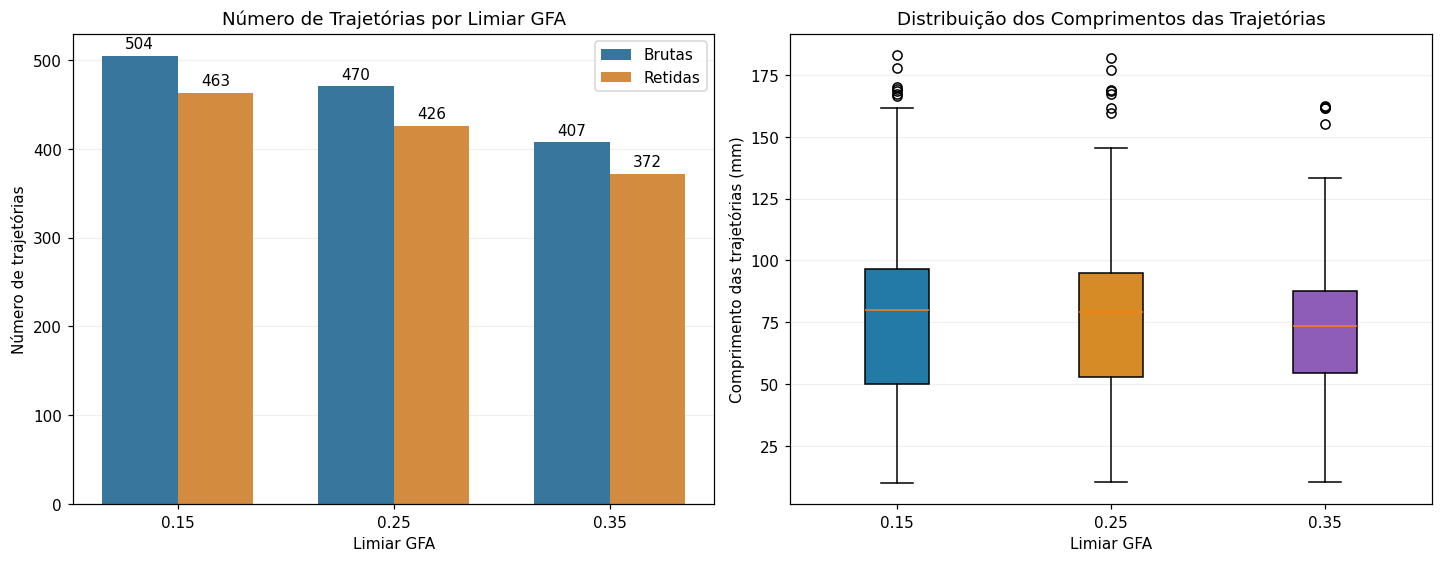

Variação das trajetórias retidas: -19.7%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)

posicoes = np.arange(len(LIMIARES_GFA))
largura = 0.35
nomes_limiares = [f"{limiar:.2f}" for limiar in LIMIARES_GFA]

brutas = axes[0].bar(posicoes - largura/2, df["n_trajetorias_brutas"], largura, color="#38769d", label="Brutas")

retidas = axes[0].bar(posicoes + largura/2, df["n_trajetorias_retidas"], largura, color="#d28b3f", label="Retidas")

axes[0].bar_label(brutas, padding=3)
axes[0].bar_label(retidas, padding=3)

axes[0].set_xticks(posicoes, nomes_limiares)
axes[0].set_xlabel("Limiar GFA")
axes[0].set_ylabel("Número de trajetórias")
axes[0].set_title("Número de Trajetórias por Limiar GFA")
axes[0].legend()


comprimentos = [comprimentos_por_limiar[limiar] for limiar in LIMIARES_GFA]

bp = axes[1].boxplot(comprimentos, patch_artist=True)

for caixa, limiar in zip(bp["boxes"], LIMIARES_GFA):
    caixa.set_facecolor(CORES_LIMIARES[limiar])

axes[1].set_xticks(posicoes + 1, nomes_limiares)
axes[1].set_xlabel("Limiar GFA")
axes[1].set_ylabel("Comprimento das trajetórias (mm)")
axes[1].set_title("Distribuição dos Comprimentos das Trajetórias")

for ax in axes:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

plt.show()


n_inicio = df["n_trajetorias_retidas"].iloc[0]
n_fim = df["n_trajetorias_retidas"].iloc[-1]

if n_inicio > 0:
    variacao = 100 * (n_fim - n_inicio) / n_inicio
    print(f"Variação das trajetórias retidas: {variacao:+.1f}%")

## **Visualização 3D das Trajetórias da Substância Branca**

- Representação tridimensional das trajetórias reconstruídas para os três limiares de GFA, permitindo comparar visualmente a quantidade, a distribuição espacial e a orientação das trajetórias.

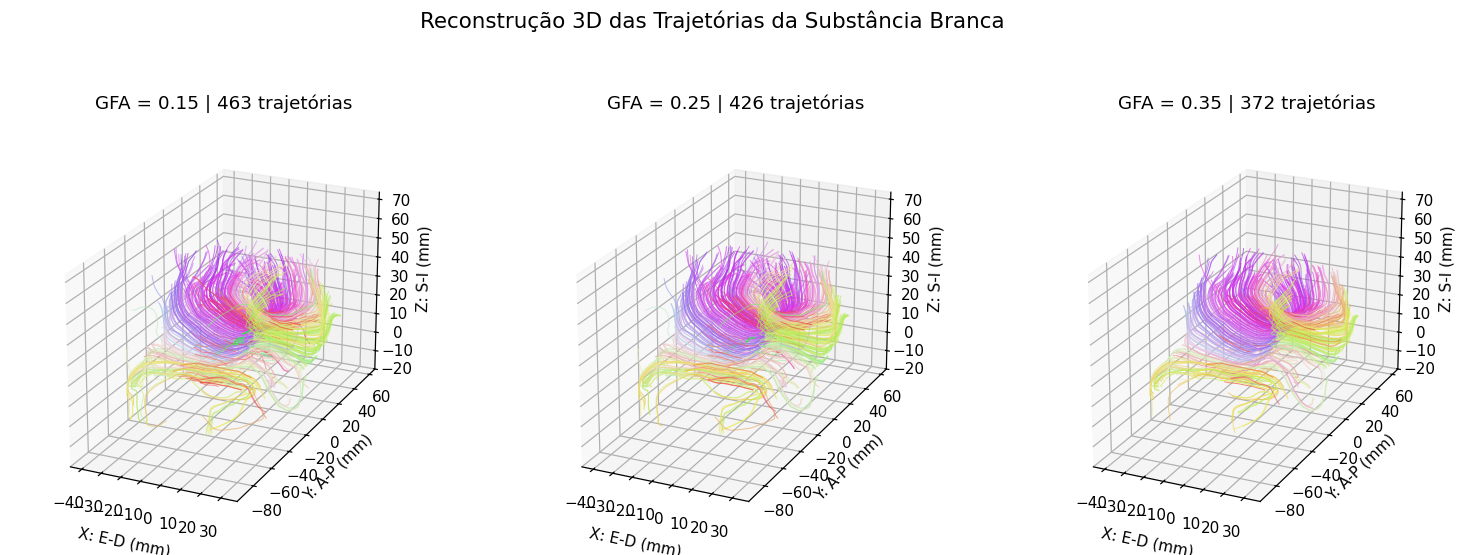

In [9]:
def cor_orientacao(track):
    direcoes = np.abs(np.diff(track, axis=0))
    orientacao = np.mean(direcoes, axis=0)
    return 0.12 + 0.80 * orientacao / np.max(orientacao)


coordenadas = np.concatenate([track for limiar in LIMIARES_GFA for track in tracks_por_limiar[limiar]])

minimos = coordenadas.min(axis=0) - 3
maximos = coordenadas.max(axis=0) + 3


fig = plt.figure(figsize=(17, 6))

for i, limiar in enumerate(LIMIARES_GFA, start=1):

    ax = fig.add_subplot(1, 3, i, projection="3d")
    tracks = tracks_por_limiar[limiar]

    for track in tracks:
        ax.plot(track[:, 0], track[:, 1], track[:, 2], color=cor_orientacao(track), linewidth=0.65, alpha=0.65)

    ax.set_title(f"GFA = {limiar:.2f} | {len(tracks)} trajetórias")

    ax.set_xlabel("X: E-D (mm)")
    ax.set_ylabel("Y: A-P (mm)")
    ax.set_zlabel("Z: S-I (mm)")

    ax.set_xlim(minimos[0], maximos[0])
    ax.set_ylim(minimos[1], maximos[1])
    ax.set_zlim(minimos[2], maximos[2])

    ax.set_box_aspect(maximos - minimos)
    ax.view_init(elev=22, azim=-65)

fig.suptitle("Reconstrução 3D das Trajetórias da Substância Branca", fontsize=14)

plt.show()

## **Visualização Interativa 3D da Tractografia**

- Visualização interativa das trajetórias reconstruídas com o limiar de GFA de referência, permitindo explorar a sua orientação espacial, os cortes de MRI e a localização das sementes.

In [10]:
import plotly.graph_objects as go
from scipy.ndimage import binary_dilation, binary_closing, binary_fill_holes, label

tracks_ref = tracks_por_limiar[LIMIAR_REFERENCIA]
fig3d = go.Figure()


mascara_cerebro = binary_dilation(white_matter, iterations=6)

def adicionar_corte(plano, visivel):

    if plano == "Sagital":
        corte = b0[x_roi, :, :]
        mascara = mascara_cerebro[x_roi, :, :]
        y, z = np.indices(corte.shape)
        indices = np.stack([np.full_like(y, x_roi), y, z], axis=-1)

    else:
        corte = b0[:, :, zi]
        mascara = mascara_cerebro[:, :, zi]
        x, y = np.indices(corte.shape)
        indices = np.stack([x, y, np.full_like(x, zi)], axis=-1)

    mascara = mascara & (corte > 0.10 * intensidade_max)
    mascara = binary_closing(mascara, iterations=2)

    rotulos, numero = label(mascara)

    if numero > 0:
        areas = np.bincount(rotulos.ravel())
        areas[0] = 0
        mascara = binary_fill_holes(rotulos == np.argmax(areas))

    coordenadas = nib.affines.apply_affine(affine, indices)
    coordenadas[~mascara] = np.nan

    fig3d.add_trace(go.Surface(x=coordenadas[:, :, 0], y=coordenadas[:, :, 1], z=coordenadas[:, :, 2], surfacecolor=corte, colorscale=[[0, "black"], [1, "white"]], cmin=0, cmax=intensidade_max, opacity=0.65, showscale=False, showlegend=True, connectgaps=False, name=f"MRI — Corte {plano}", visible=visivel))


adicionar_corte("Sagital", True)
adicionar_corte("Axial", "legendonly")


linhas = [[[], [], []] for _ in range(3)]

for track in tracks_ref:
    pontos = np.asarray(track)[::2]

    for i in range(len(pontos) - 1):
        p1, p2 = pontos[i], pontos[i + 1]
        eixo = np.argmax(np.abs(p2 - p1))

        linhas[eixo][0].extend([p1[0], p2[0], None])
        linhas[eixo][1].extend([p1[1], p2[1], None])
        linhas[eixo][2].extend([p1[2], p2[2], None])

nomes = ["Esquerda-Direita", "Anterior-Posterior", "Superior-Inferior"]
cores = ["#d44854", "#209b6f", "#3b6dd8"]

for i in range(3):
    fig3d.add_trace(go.Scatter3d(x=linhas[i][0], y=linhas[i][1], z=linhas[i][2], mode="lines", line=dict(color=cores[i], width=2.5), name=nomes[i]))


fig3d.add_trace(go.Scatter3d(x=seeds[:, 0], y=seeds[:, 1], z=seeds[:, 2], mode="markers", marker=dict(size=2.5, color="yellow"), name=f"Sementes ({len(seeds)})", visible="legendonly"))

fig3d.update_layout(title=f"Tractografia 3D — GFA = {LIMIAR_REFERENCIA:.2f} ({len(tracks_ref)} trajetórias)", height=750, scene=dict(xaxis_title="X: E-D (mm)", yaxis_title="Y: A-P (mm)", zaxis_title="Z: S-I (mm)", aspectmode="data", camera=dict(eye=dict(x=1.65, y=-1.55, z=1.05))))

fig3d.show()

________________________________________________________________________________________________________________________________________________________________

**DIPY Demonstrador | Reconstrução Tridimensional das Conexões Cerebrais (dMRI)**